# Reporte descriptivo de contratación — SECOP 2

Monitoría de investigación - Beca Avanza, Universidad de los Andes. **Entregable 3.**

Describe la contratación de las entidades elegidas con los datos extraídos y procesados por el pipeline del repositorio:

1. Se extraen **contratos** y **procesos** del portal de datos abiertos y se unen al nivel de contrato (`construir_base_contratos`, en `src/flujo_vigia.py`).
2. Las cifras se calculan con las funciones de `src/indicadores.py` y `src/tendencias.py`, las mismas que usa la app.

Para otro alcance basta con cambiar la celda de parámetros y volver a ejecutar todo.

Empecemos importando las librerías y los módulos del proyecto

In [1]:
import sys
sys.path.append('..')
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src import indicadores as ind
from src import tendencias as ten
from src.flujo_vigia import construir_base_contratos

## 1. Parámetros

- `ENTIDADES`: nombre de cada entidad tal como aparece en SECOP 2, con la sigla que se usa en las tablas.
- `DESDE` / `HASTA`: rango de la fecha de firma del contrato.
- `MARGEN_MESES`: cuántos meses antes de `DESDE` se buscan los procesos (el proceso siempre precede al contrato).

In [2]:
ENTIDADES = {
    'AGENCIA NACIONAL DE TIERRAS - ANT': 'ANT',
    'UNP': 'UNP',
    'AGENCIA PARA LA REINCORPORACIÓN Y LA NORMALIZACIÓN': 'ARN',
}
DESDE = '2022-01-01'
HASTA = '2026-11-23'
MARGEN_MESES = 6

## 2. Extracción y procesamiento

La primera ejecución descarga los datos del portal (tarda unos minutos) y los guarda en `data/processed/`. Las siguientes los leen de ahí. Para volver a descargar, se borra el archivo.

Solo se guardan las columnas que usa el reporte: la tabla original trae más de 150, entre ellas datos personales de representantes legales y cuentas bancarias que el reporte no necesita.

In [3]:
COLUMNAS = [
    'nombre_entidad', 'id_contrato', 'proceso_de_compra', 'estado_contrato',
    'tipo_de_contrato', 'modalidad_de_contratacion', 'justificacion_modalidad_de',
    'fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato',
    'dias_firma_a_inicio', 'dias_inicio_a_fin', 'proveedor_adjudicado', 'documento_proveedor',
    'tipodocproveedor', 'es_pyme', 'valor_del_contrato', 'valor_pagado', 'dias_adicionados',
    'destino_gasto', 'origen_de_los_recursos', 'precio_base', 'respuestas_al_procedimiento',
    'fecha_de_publicacion_del',
]
FECHAS = ['fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato',
          'fecha_de_publicacion_del']

archivo = Path('../data/processed') / f"reporte_{'_'.join(ENTIDADES.values())}_{DESDE}_{HASTA}.csv.gz"

if archivo.exists():
    df = pd.read_csv(archivo, parse_dates=FECHAS, low_memory=False)
else:
    config = {
        'filtros': {'nombre_entidad': list(ENTIDADES),
                    'fecha_de_firma': {'desde': DESDE, 'hasta': HASTA}},
        'margen_meses_procesos': MARGEN_MESES,
    }
    base = construir_base_contratos(config, limite=None)
    df = base[[c for c in COLUMNAS if c in base.columns]]
    df.to_csv(archivo, index=False)

for col in ['valor_del_contrato', 'valor_pagado', 'dias_adicionados', 'precio_base',
            'respuestas_al_procedimiento']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['entidad'] = df['nombre_entidad'].map(ENTIDADES)
df['año'] = df['fecha_de_firma'].dt.year
df.shape

(60933, 26)

Contratos por entidad

In [4]:
df['entidad'].value_counts()

entidad
ANT    40441
UNP    12578
ARN     7914
Name: count, dtype: int64

## 3. Calidad de los datos

Revisiones de consistencia de `ind.calidad_datos`. No corrigen nada: señalan registros que conviene mirar antes de calcular estadísticas.

In [5]:
for sigla, g in df.groupby('entidad'):
    print(sigla, f'({len(g)} contratos)')
    print(ind.calidad_datos(g).to_string(index=False), '\n')

ANT (40441 contratos)
                                         revisión  casos
           Firma posterior al inicio del contrato     13
                   Sin fecha de inicio o de firma    206
                               Valor cero o vacío     19
Valor más de 1.000 veces la mediana ($38.108.268)      6 

ARN (7914 contratos)
                      revisión  casos
Sin fecha de inicio o de firma      2
            Valor cero o vacío     26 

UNP (12578 contratos)
                                         revisión  casos
           Firma posterior al inicio del contrato      2
                   Sin fecha de inicio o de firma     25
                               Valor cero o vacío     18
Valor más de 1.000 veces la mediana ($39.666.667)     59 



Valores faltantes en las columnas del reporte (%)

In [6]:
(100 * df.isna().mean()).round(1).sort_values(ascending=False).head(10)

fecha_de_inicio_del_contrato    0.4
dias_firma_a_inicio             0.4
dias_inicio_a_fin               0.4
respuestas_al_procedimiento     0.2
precio_base                     0.2
fecha_de_publicacion_del        0.2
id_contrato                     0.0
proceso_de_compra               0.0
tipo_de_contrato                0.0
nombre_entidad                  0.0
dtype: float64

## 4. Panorama general

Cifras de cabecera por entidad (`ind.resumen`). Valores en miles de millones de pesos.

In [7]:
resumen = pd.DataFrame({sigla: ind.resumen(g) for sigla, g in df.groupby('entidad')}).T
resumen['valor_total'] = resumen['valor_total'] / 1e9
resumen['valor_mediano'] = resumen['valor_mediano'] / 1e6
resumen = resumen.rename(columns={
    'valor_total': 'valor total (miles de millones)', 'valor_mediano': 'valor mediano (millones)',
    'pct_directa': '% contratación directa', 'pct_con_prorroga': '% con prórroga',
    'pct_firma_tardia': '% firmado tras iniciar'})
resumen.style.format(precision=1, decimal=',', thousands='.').format(precision=0, thousands='.', subset=['contratos'])

,contratos,valor total (miles de millones),valor mediano (millones),% contratación directa,% con prórroga,% firmado tras iniciar
ANT,40.441,"4.360,4","38,1","97,6","9,8","0,0"
ARN,7.914,"910,8","48,5","97,7","3,5","0,0"
UNP,12.578,"10.908,1","39,7","97,1","22,5","0,0"


## 5. Contratación por año

Número de contratos y valor por año de firma. **El último año está incompleto** (llega hasta `HASTA`).

In [8]:
por_anio = df.groupby(['año', 'entidad']).agg(contratos=('id_contrato', 'size'),
                                             valor=('valor_del_contrato', 'sum'))
por_anio['valor'] = por_anio['valor'] / 1e9
por_anio.unstack('entidad').round(1)

contratos               valor               
entidad       ANT   ARN   UNP     ANT    ARN     UNP
año                                                 
2022         1466  1310  1503   117.3  151.6  1367.7
2023         5542  2163  2379   505.8  209.2  6540.1
2024        11870  1511  2443  2424.6  143.2   961.4
2025        11746  1590  3266   708.1  284.7  1441.4
2026         9817  1340  2987   604.6  122.0   597.5

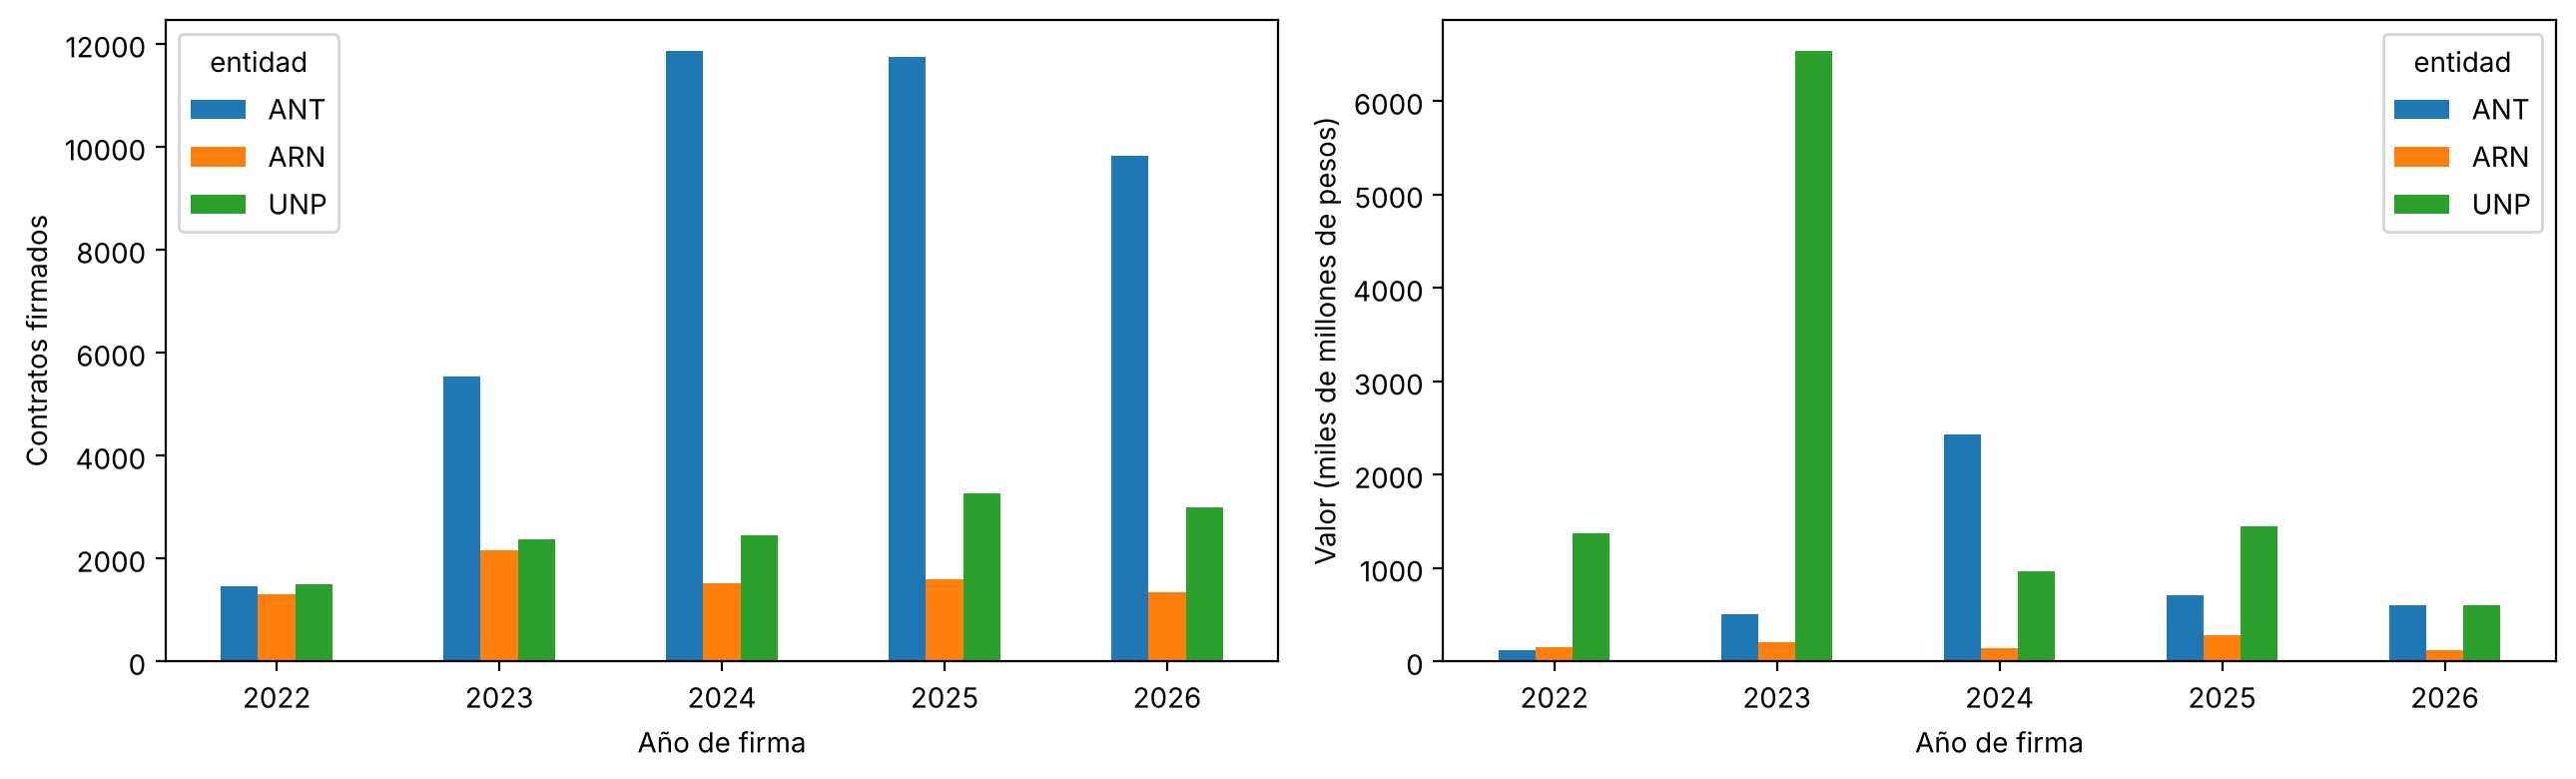

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_anio['contratos'].unstack('entidad').plot.bar(ax=ax[0])
ax[0].set_ylabel('Contratos firmados')
por_anio['valor'].unstack('entidad').plot.bar(ax=ax[1])
ax[1].set_ylabel('Valor (miles de millones de pesos)')
for a in ax:
    a.set_xlabel('Año de firma')
    a.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 6. Modalidad y tipo de contrato

Contratos y valor por modalidad de contratación (`ind.por_modalidad`), en porcentaje del total de cada entidad.

In [10]:
modalidades = []
for sigla, g in df.groupby('entidad'):
    t = ind.por_modalidad(g)
    modalidades.append(pd.DataFrame({
        'entidad': sigla,
        '% contratos': 100 * t['contratos'] / t['contratos'].sum(),
        '% valor': 100 * t['valor'] / t['valor'].sum()}))
pd.concat(modalidades).reset_index().pivot(index='modalidad', columns='entidad').fillna(0).round(1)

% contratos              \
entidad                                                    ANT   ARN   UNP   
modalidad                                                                    
Concurso de méritos abierto                                0.0   0.2   0.0   
Contratación Directa (con ofertas)                         0.2   0.0   0.1   
Contratación directa                                      97.4  97.7  97.0   
Contratación régimen especial                              2.2   0.3   0.0   
Contratación régimen especial (con ofertas)                0.0   0.0   0.0   
Licitación pública                                         0.0   0.2   0.1   
Licitación pública Obra Publica                            0.0   0.0   0.0   
Mínima cuantía                                             0.1   0.6   1.0   
Seleccion Abreviada Menor Cuantia Sin Manifesta...         0.0   0.0   0.0   
Selección Abreviada de Menor Cuantía                       0.0   0.6   1.4   
Selección abreviada subasta inversa                        0.1   0.5   0.3   

                                                   % valor              
entidad                                                ANT   ARN   UNP  
modalidad                                                               
Concurso de méritos abierto                            0.0   1.1   0.0  
Contratación Directa (con ofertas)                    48.2   0.1   0.2  
Contratación directa                                  43.1  60.4  13.7  
Contratación régimen especial                          5.5  12.4   0.3  
Contratación régimen especial (con ofertas)            0.2   0.9   0.0  
Licitación pública                                     0.0  12.9   1.2  
Licitación pública Obra Publica                        0.1   0.0   0.0  
Mínima cuantía                                         0.1   0.1   0.1  
Seleccion Abreviada Menor Cuantia Sin Manifesta...     0.0   0.0   0.0  
Selección Abreviada de Menor Cuantía                   0.1   8.4  82.8  
Selección abreviada subasta inversa                    2.7   3.6   1.8

Tipo de contrato: porcentaje de los contratos de cada entidad

In [11]:
(100 * pd.crosstab(df['tipo_de_contrato'], df['entidad'], normalize='columns')).round(1).sort_values('ANT', ascending=False).head(8)

entidad,ANT,ARN,UNP
tipo_de_contrato,,,
Prestación de servicios,97.2,95.5,97.4
Otro,2.2,0.9,0.3
Arrendamiento de inmuebles,0.4,2.1,1.0
Compraventa,0.1,0.5,0.6
Comodato,0.0,0.0,0.0
Consultoría,0.0,0.2,0.0
Comisión,0.0,0.0,0.0
Arrendamiento de muebles,0.0,0.0,0.1


### Causal de la contratación directa

La contratación directa solo procede en las causales de la Ley 1150 de 2007 (`ind.justificacion_directa`). Se muestran las cinco más usadas en cada entidad.

In [12]:
for sigla, g in df.groupby('entidad'):
    print(sigla)
    print(ind.justificacion_directa(g)[['contratos', '% de los directos']].head(5), '\n')

ANT
                                                    contratos  \
causal                                                          
Servicios profesionales y apoyo a la gestión            39132   
Arrendamiento de inmuebles                                178   
Contratos o convenios Interadministrativos (con...         56   
Contratos o convenios Interadministrativos (val...         39   
No existe pluralidad de oferentes en el mercado            27   

                                                    % de los directos  
causal                                                                 
Servicios profesionales y apoyo a la gestión                    99.17  
Arrendamiento de inmuebles                                       0.45  
Contratos o convenios Interadministrativos (con...               0.14  
Contratos o convenios Interadministrativos (val...               0.10  
No existe pluralidad de oferentes en el mercado                  0.07   

ARN
                              

## 7. Prestación de servicios profesionales frente al resto

Los contratos de prestación de servicios profesionales son la nómina de contratistas de la entidad: muchos contratos de valor pequeño que dominan cualquier conteo. `ind.comparar_prestacion` los separa del resto.

In [13]:
grupos = {sigla: ind.comparar_prestacion(g) for sigla, g in df.groupby('entidad')}
tabla = pd.concat(grupos, names=['entidad', 'grupo'])
tabla['valor'] = tabla['valor'] / 1e9
tabla['valor_mediano'] = tabla['valor_mediano'] / 1e6
tabla.rename(columns={'valor': 'valor (miles de millones)',
                      'valor_mediano': 'valor mediano (millones)'}).style.format(precision=1, decimal=',', thousands='.')

## 8. Valor de los contratos

Estadísticas descriptivas del valor por entidad (millones de pesos)

In [14]:
valores = df.groupby('entidad')['valor_del_contrato'].describe(percentiles=[.25, .5, .75, .9, .99])
valores.iloc[:, 1:] = valores.iloc[:, 1:] / 1e6
valores.round(1)

,count,mean,std,min,25%,50%,75%,90%,99%,max
entidad,,,,,,,,,,
ANT,40441.0,107.8,4370.9,0.0,26.8,38.1,54.6,77.3,165.4,500000.0
ARN,7914.0,115.1,975.1,0.0,25.7,48.5,65.5,94.9,1345.2,48010.3
UNP,12578.0,867.2,11660.1,0.0,23.4,39.7,60.0,83.6,11723.7,491445.6


Contratos por orden de magnitud del valor (`ind.distribucion_valores`)

In [15]:
pd.DataFrame({sigla: ind.distribucion_valores(g)['contratos'] for sigla, g in df.groupby('entidad')}).fillna(0).astype(int)

,ANT,ARN,UNP
valor_del_contrato,,,
menos de 1M,2,2,3
1M – 10M,932,305,690
10M – 100M,37764,6953,11111
100M – 1.000M,1579,542,463
1.000M – 10.000M,118,77,155
10.000M – 100.000M,23,9,111
más de 100.000M,4,0,27


Diagrama de caja del valor en escala logarítmica, por entidad y grupo. En escala lineal los contratos más grandes aplastan a los demás.

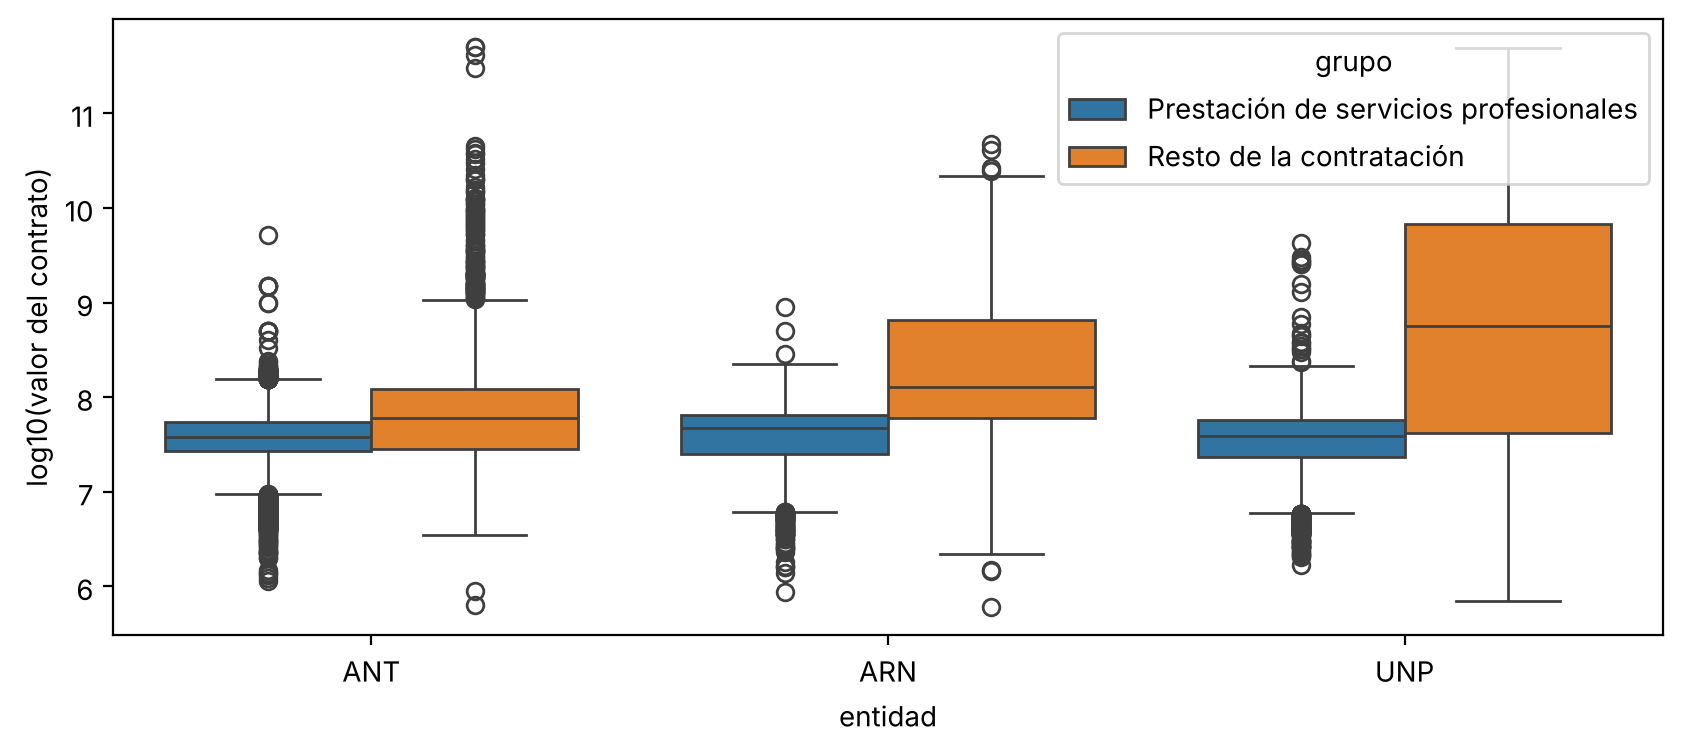

In [16]:
df['grupo'] = ind.grupo_prestacion(df)
df['log10_valor'] = np.log10(df['valor_del_contrato'].where(df['valor_del_contrato'] > 0))
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='entidad', y='log10_valor', hue='grupo')
plt.ylabel('log10(valor del contrato)')
plt.show()

## 9. Tiempos del contrato

Días entre la firma y el inicio (`ind.distribucion_firma_a_inicio`). Un contrato firmado después de su inicio es una alerta.

In [17]:
tramos = {sigla: ind.distribucion_firma_a_inicio(g).sum(axis=1) for sigla, g in df.groupby('entidad')}
pd.DataFrame(tramos)

,ANT,ARN,UNP
Firmado tras iniciar,13,0,2
Mismo día,9821,1704,4526
1 a 7 días,28089,5701,7170
8 a 30 días,2169,498,844
Más de 30 días,143,9,11


Duración planeada del contrato (inicio → fin), en días

In [18]:
df.groupby('entidad')['dias_inicio_a_fin'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
ANT,40235.0,174.6,97.3,0.0,123.0,160.0,214.5,4382.0
ARN,7912.0,266.1,117.3,0.0,177.0,317.0,342.0,2191.0
UNP,12553.0,224.4,120.5,0.0,123.0,226.0,340.0,2191.0


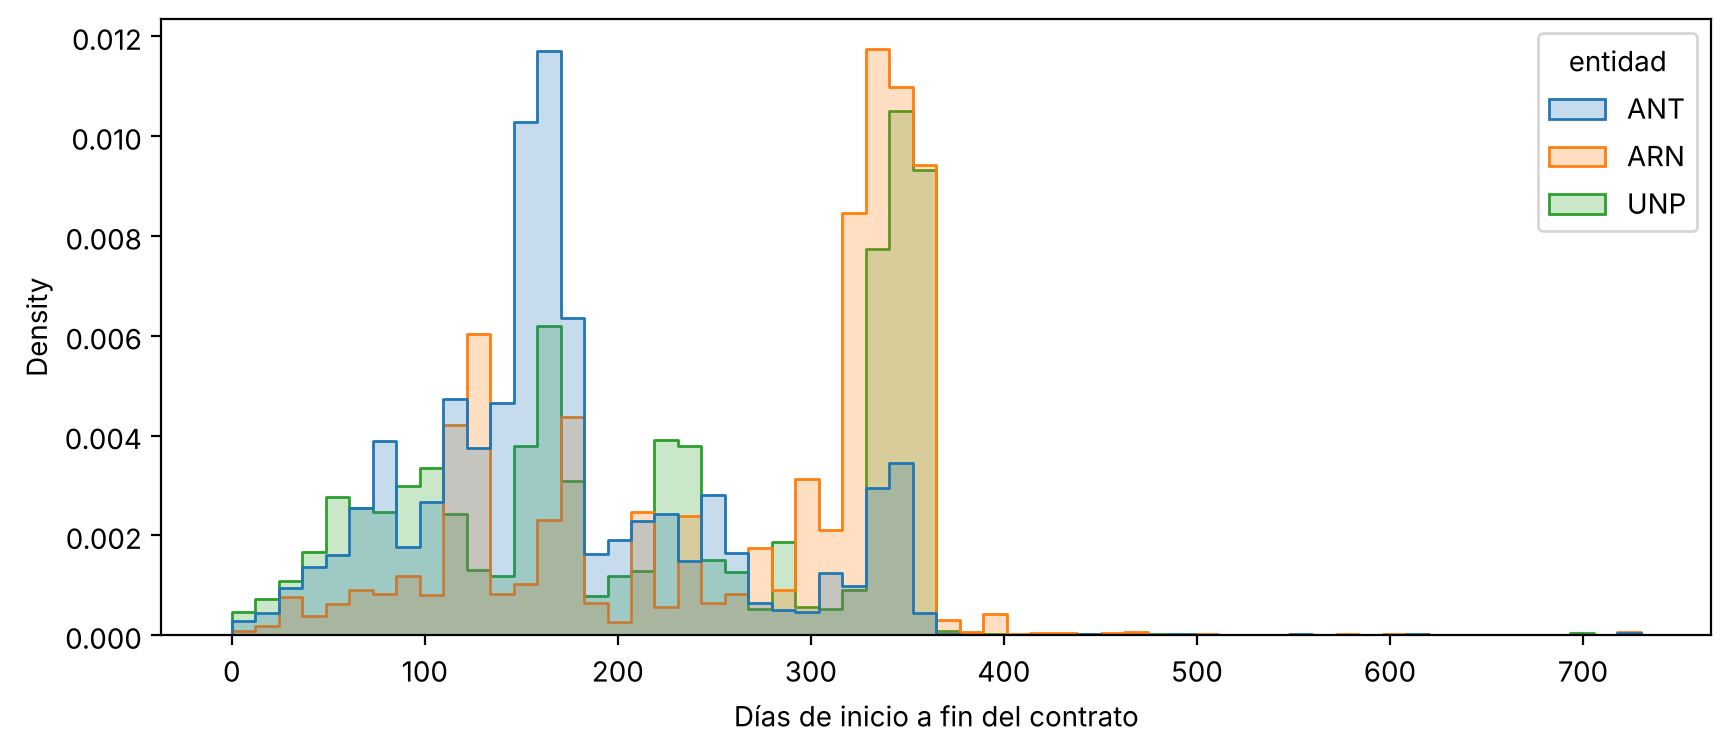

In [19]:
plt.figure(figsize=(10, 4))
sns.histplot(data=df[df['dias_inicio_a_fin'].between(0, 730)], x='dias_inicio_a_fin',
             hue='entidad', stat='density', common_norm=False, bins=60, element='step')
plt.xlabel('Días de inicio a fin del contrato')
plt.show()

Días entre la publicación del proceso y la firma del contrato

In [20]:
df['dias_publicacion_a_firma'] = (df['fecha_de_firma'] - df['fecha_de_publicacion_del']).dt.days
df.groupby('entidad')['dias_publicacion_a_firma'].describe(percentiles=[.5, .9]).round(1)

,count,mean,std,min,50%,90%,max
entidad,,,,,,,
ANT,40347.0,2.4,5.3,0.0,1.0,6.0,194.0
ARN,7897.0,2.9,7.9,0.0,0.0,8.0,123.0
UNP,12544.0,1.7,6.7,0.0,0.0,3.0,160.0


## 10. Competencia

Ofertas recibidas según la modalidad (`ind.ofertas_por_modalidad`). Cero ofertas es lo normal en contratación directa, donde no hay convocatoria; en una modalidad competitiva sí es una señal.

In [21]:
for sigla, g in df.groupby('entidad'):
    print(sigla)
    print(ind.ofertas_por_modalidad(g), '\n')

ANT
respuestas_al_procedimiento                  Sin ofertas  Una oferta  \
modalidad_de_contratacion                                              
Contratación directa                               39299           0   
Contratación régimen especial                        885           0   
Contratación Directa (con ofertas)                     0          66   
Mínima cuantía                                         1           9   
Selección abreviada subasta inversa                    8           2   
Selección Abreviada de Menor Cuantía                   7           1   
Contratación régimen especial (con ofertas)            0           4   
Concurso de méritos abierto                            0           2   
Licitación pública                                     0           0   
Licitación pública Obra Publica                        1           0   

respuestas_al_procedimiento                  Dos o más  Total  
modalidad_de_contratacion                                      
Con

## 11. Proveedores

Qué parte de los contratos y del valor se llevan los 10 mayores proveedores de cada entidad (`ind.concentracion_proveedores`). Se reportan solo porcentajes: muchos proveedores son personas naturales.

In [22]:
conc = {}
for sigla, g in df.groupby('entidad'):
    c = ind.concentracion_proveedores(g, n=10)
    conc[sigla] = {'proveedores distintos': c['proveedores'],
                   'contratos por proveedor': len(g) / c['proveedores'],
                   '% de contratos del top 10': c['pct_contratos'],
                   '% del valor del top 10': c['pct_valor']}
pd.DataFrame(conc).T.style.format(precision=1, decimal=',', thousands='.').format(precision=0, thousands='.', subset=['proveedores distintos'])

,proveedores distintos,contratos por proveedor,% de contratos del top 10,% del valor del top 10
ANT,14.841,"2,7","0,1","49,5"
ARN,2.987,"2,6","0,5","33,5"
UNP,4.083,"3,1","0,6","48,1"


Curva de concentración: porcentaje del valor acumulado por los proveedores, de mayor a menor (`ind.curva_concentracion`). La diagonal sería un reparto igual entre todos.

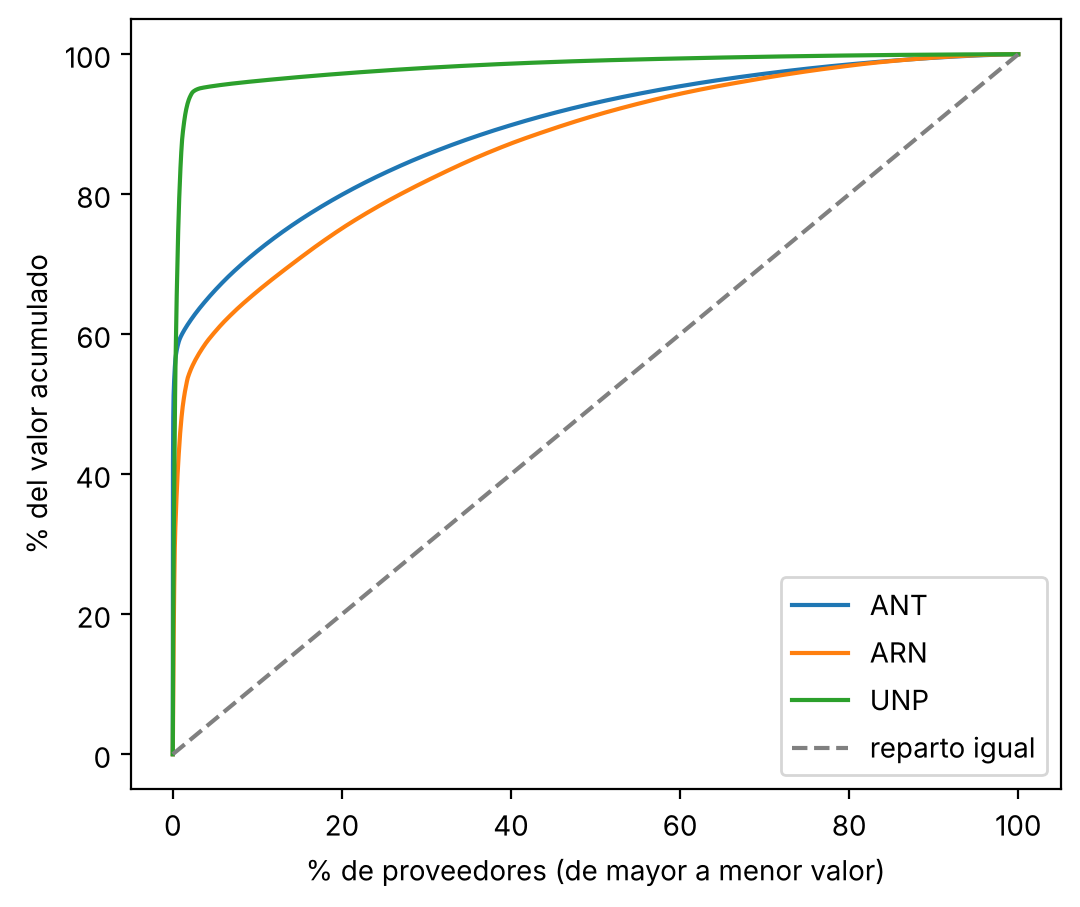

In [23]:
plt.figure(figsize=(6, 5))
for sigla, g in df.groupby('entidad'):
    curva = ind.curva_concentracion(g)
    plt.plot(curva['pct_proveedores'], curva['pct_valor'], label=sigla)
plt.plot([0, 100], [0, 100], color='grey', linestyle='--', label='reparto igual')
plt.xlabel('% de proveedores (de mayor a menor valor)')
plt.ylabel('% del valor acumulado')
plt.legend()
plt.show()

## 12. Prórrogas

Porcentaje de contratos con días adicionados, por año de firma. Solo se cuentan contratos cuya **fecha de fin ya pasó**: uno que sigue en ejecución todavía puede prorrogarse, y contarlo haría ver los años recientes con menos prórrogas de las que tendrán.

Aun así, el último año no es comparable: de los contratos firmados ese año solo han terminado los más cortos. Por eso se muestra también cuántos contratos hay detrás de cada porcentaje.

In [24]:
terminados = df[df['fecha_de_fin_del_contrato'] < pd.Timestamp(HASTA)]
prorroga = terminados.assign(con_prorroga=terminados['dias_adicionados'] > 0)
tasa = 100 * prorroga.groupby(['año', 'entidad'])['con_prorroga'].mean().unstack('entidad')
n = prorroga.groupby(['año', 'entidad']).size().unstack('entidad')
pd.concat({'% con prórroga': tasa.round(1), 'contratos terminados': n}, axis=1)

% con prórroga            contratos terminados            
entidad            ANT  ARN   UNP                  ANT   ARN   UNP
año                                                               
2022               2.0  0.5   4.3                 1465  1308  1502
2023               0.9  0.0  18.6                 5538  2159  2365
2024              12.1  3.2  15.4                11861  1499  2435
2025               9.0  2.2  41.9                11656  1540  3255
2026              19.5  1.9  76.2                 5746    52   618

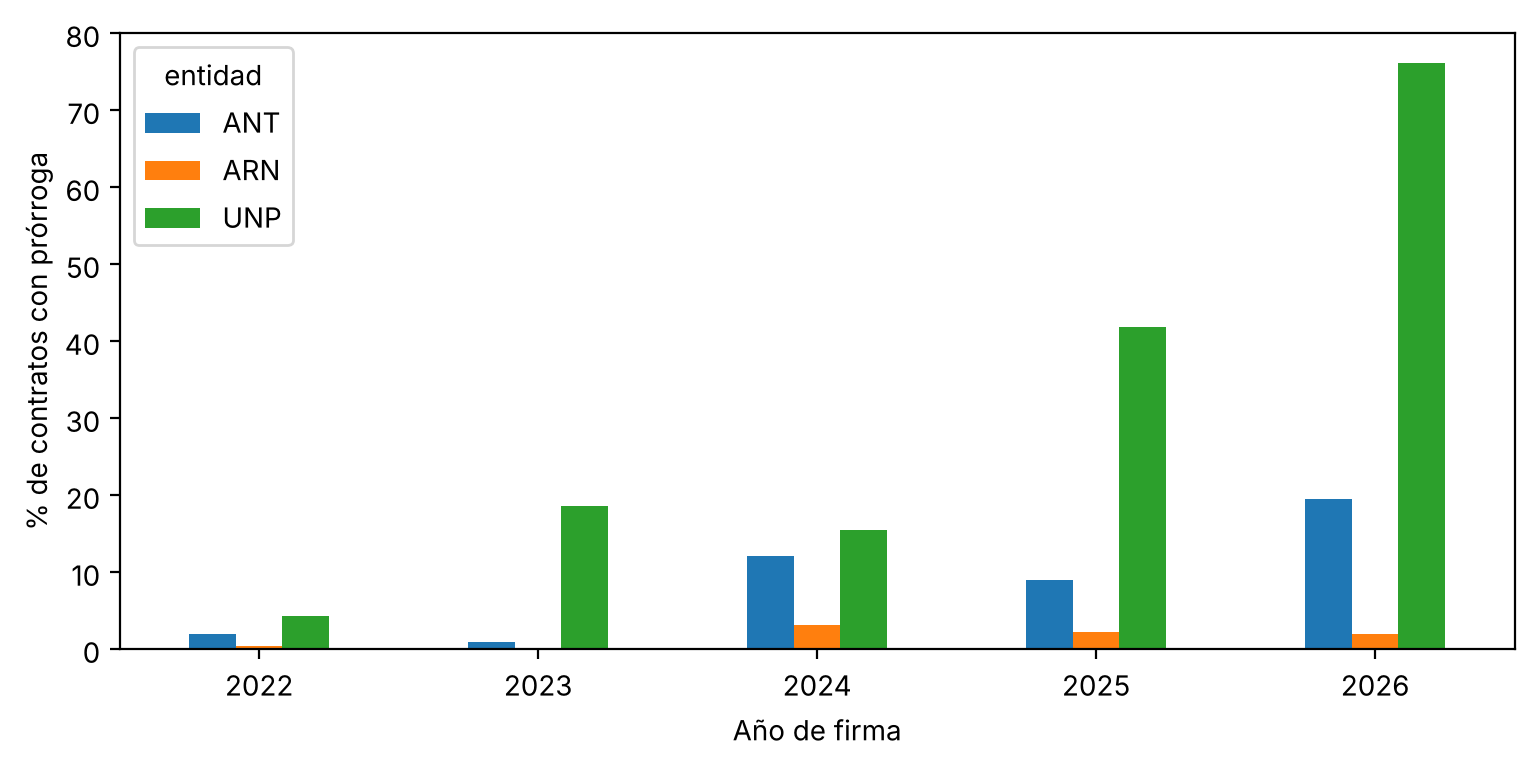

In [25]:
tasa.plot.bar(figsize=(9, 4))
plt.ylabel('% de contratos con prórroga')
plt.xlabel('Año de firma')
plt.xticks(rotation=0)
plt.show()

Días adicionados en los contratos con prórroga

In [26]:
prorroga[prorroga['con_prorroga']].groupby('entidad')['dias_adicionados'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
ANT,3682.0,85.1,32.0,1.0,61.0,92.0,92.0,547.0
ARN,89.0,55.7,68.0,6.0,16.0,16.0,89.0,407.0
UNP,2716.0,84.9,34.5,1.0,61.0,86.0,115.0,366.0


## 13. Cambios en el tiempo

Contratos por trimestre de firma (`ten.serie_temporal`). El trimestre en curso se excluye porque está incompleto.

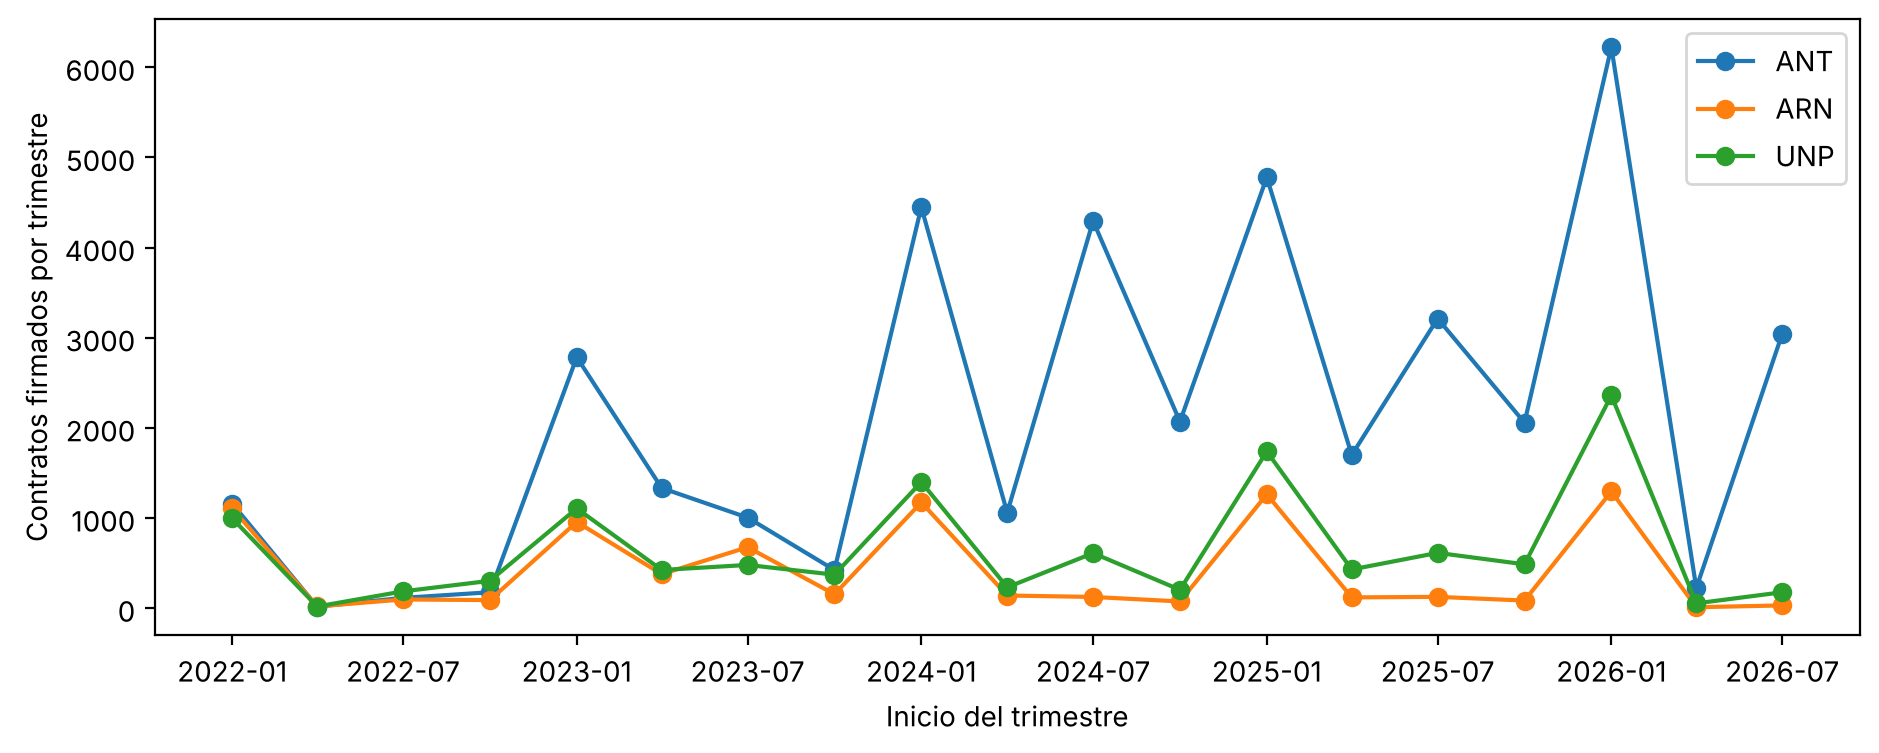

In [27]:
serie = ten.serie_temporal(df, periodo='QE')
serie['entidad'] = serie['entidad'].map(ENTIDADES)
serie = serie[serie['completo']]
plt.figure(figsize=(11, 4))
for sigla, s in serie.groupby('entidad'):
    plt.plot(s['inicio'], s['contratos'], marker='o', label=sigla)
plt.ylabel('Contratos firmados por trimestre')
plt.xlabel('Inicio del trimestre')
plt.legend()
plt.show()

Contratos firmados por mes del año (todas las entidades y años). Muestra el ciclo de la contratación de servicios a comienzo de año.

In [28]:
serie.pivot(index='periodo', columns='entidad', values='contratos')

entidad,ANT,ARN,UNP
periodo,,,
2022Q1,1160,1106,996
2022Q2,16,19,18
2022Q3,114,96,186
2022Q4,176,89,303
2023Q1,2783,956,1106
2023Q2,1332,377,423
2023Q3,1004,676,479
2023Q4,423,154,371
2024Q1,4448,1173,1399


Contratos firmados por mes en los años con elección presidencial (2022 y 2026)

In [29]:
elecciones = df[df['año'].isin([2022, 2026])]
elecciones.groupby([elecciones['fecha_de_firma'].dt.to_period('M'), 'entidad']).size().unstack('entidad').fillna(0).astype(int)

entidad,ANT,ARN,UNP
fecha_de_firma,,,
2022-01,1151,1101,966
2022-02,9,0,19
2022-03,0,5,11
2022-04,5,6,3
2022-05,4,6,3
2022-06,7,7,12
2022-07,35,52,55
2022-08,42,3,75
2022-09,37,41,56


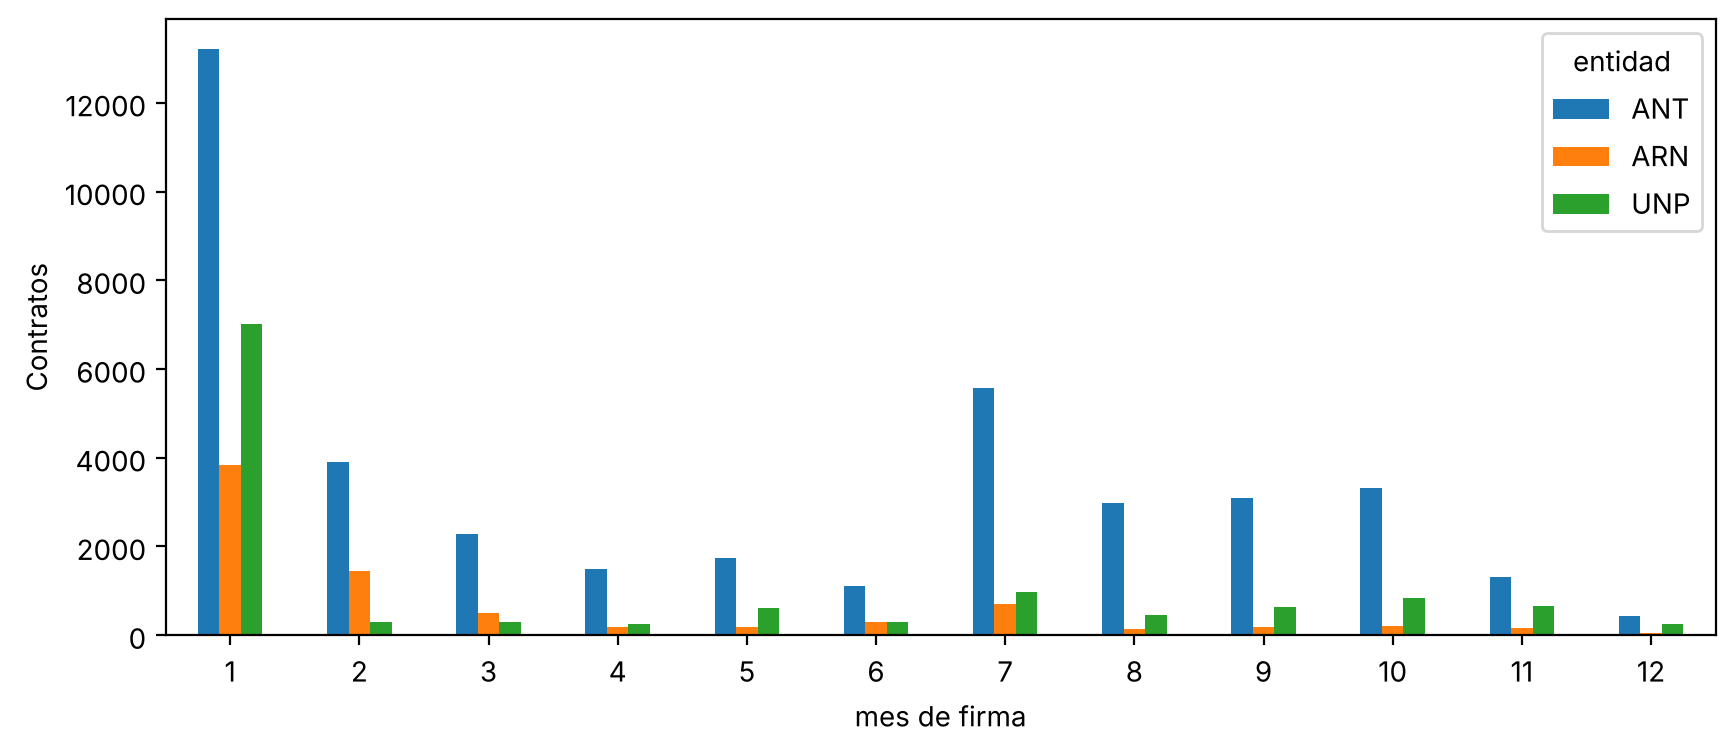

In [30]:
mes = df.groupby([df['fecha_de_firma'].dt.month, 'entidad']).size().unstack('entidad')
mes.index.name = 'mes de firma'
mes.plot.bar(figsize=(10, 4))
plt.ylabel('Contratos')
plt.xticks(rotation=0)
plt.show()

## 14. Conclusiones

**Alcance:** 60.933 contratos firmados entre el 1 de enero de 2022 y el 23 de noviembre de 2026 (ANT 40.441, UNP 12.578, ARN 7.914). El 99,8 % encontró su proceso en la tabla de procesos.

**1. Por número, la contratación es casi toda directa y de servicios profesionales.**
- Más del 97 % de los contratos de las tres entidades es contratación directa.
- Dentro de la directa, la causal "servicios profesionales y apoyo a la gestión" es el 99,2 % (ANT), 97,7 % (UNP) y 96,5 % (ARN).
- El valor mediano de un contrato es parecido en las tres: entre 38 y 49 millones de pesos.

**2. Por valor, la lectura cambia.**
- Los servicios profesionales son el 94 – 97 % de los contratos, pero solo el 39 % del valor en la ANT, el 40 % en la ARN y el 5 % en la UNP.
- **UNP:** de $10,9 billones, el 82,8 % se contrató por selección abreviada de menor cuantía (1,4 % de los contratos). Son contratos de prestación de servicios de hasta $491.000 millones firmados en diciembre de 2023, que explican el pico de valor de ese año.
- **ANT:** el 48,2 % del valor está en "contratación directa (con ofertas)" (0,2 % de los contratos): contratos de tipo "Otro" de $300.000 a $500.000 millones firmados en 2024, que explican su pico de ese año.
- Por eso los indicadores se leen separando los dos grupos (sección 7).

**3. Tiempos y competencia corresponden a la modalidad.**
- La mitad de los contratos se firma el mismo día o al día siguiente de publicar el proceso, y casi todos no tienen ofertas. Es lo esperado en contratación directa, no una señal por sí sola.
- Solo 15 contratos se firmaron después de su fecha de inicio (13 en la ANT, 2 en la UNP).

**4. Proveedores:** entre 2,6 y 3,1 contratos por proveedor. Los 10 mayores tienen menos del 1 % de los contratos, pero entre el 34 % (ARN) y el 50 % (ANT) del valor.

**5. Prórrogas:** el 22,5 % de los contratos de la UNP tiene días adicionados, frente al 9,8 % de la ANT y el 3,5 % de la ARN. Entre los contratos ya terminados de la UNP, pasa de 4,3 % (2022) a 41,9 % (2025); 2026 no es comparable todavía.

**6. Ciclo anual:** enero concentra la mayor parte de las firmas (renovación de contratistas). En 2022 y 2026, de febrero a junio casi no se firmaron contratos; coincide con la restricción a la contratación directa de la Ley de Garantías antes de la elección presidencial.

**Calidad de los datos:** 233 contratos sin fecha de inicio o de firma y 63 con valor cero o vacío. Los valores más de 1.000 veces la mediana corresponden a los contratos grandes descritos en el punto 2, no a errores de digitación.